In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio

from rasterio.mask import mask

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    cohen_kappa_score
)

import matplotlib.pyplot as plt

In [2]:
# -------------------------------
# Krishna (Source)
# -------------------------------

KRISHNA_IMAGE = r"C:\Users\snvra\NISAR_Data_project\Data\krishsatemb2019_24\Krishsatemb2024.tif"

KRISHNA_GT = r"C:\Users\snvra\NISAR_Data_project\Data\krishna_gt\train_2024.shp"

KRISHNA_AOI = r"C:\Users\snvra\NISAR_Data_project\Data\Shapefiles\krishna_east_div\krishna_east_div.shp"


# -------------------------------
# Malad (Target)
# -------------------------------

MALAD_IMAGE = r"Malad_Mosaic.tif"

MALAD_GT = r"C:\Users\snvra\NISAR_Data_project\Data\malad_gt\malad_gt.shp"

MALAD_AOI = r"C:\Users\snvra\NISAR_Data_project\Data\Shapefiles\Malad_MH\Malad_MH.shp"


# -------------------------------
# Output
# -------------------------------

OUTPUT_DIR = r"C:\Users\snvra\NISAR_Data_project\classifier models"

os.makedirs(OUTPUT_DIR, exist_ok=True)

In [3]:
krishna_gt = gpd.read_file(KRISHNA_GT)

krishna_aoi = gpd.read_file(KRISHNA_AOI)

print("GT polygons :", len(krishna_gt))
print("AOI polygons :", len(krishna_aoi))

GT polygons : 14
AOI polygons : 1


In [4]:
with rasterio.open(KRISHNA_IMAGE) as src:

    print("Raster size :", src.width, src.height)

    print("Bands :", src.count)

    print("CRS :", src.crs)

    print("Datatype :", src.dtypes)

    print("Transform :")

    print(src.transform)

Raster size : 2102 2236
Bands : 64
CRS : EPSG:4326
Datatype : ('float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64', 'float64')
Transform :
| 0.00, 0.00, 80.87|
| 0.00,-0.00, 15.91|
| 0.00, 0.00, 1.00|


In [5]:
with rasterio.open(KRISHNA_IMAGE) as src:

    img = src.read()        # (64, rows, cols)

print("Shape :", img.shape)

print("Minimum :", img.min())
print("Maximum :", img.max())

print("Mean :", img.mean())

print("Std :", img.std())

print("Total pixels :", img.size)

print("Zero values :", np.sum(img == 0))

print("Percentage zeros :",
      100 * np.sum(img == 0) / img.size)

Shape : (64, 2236, 2102)
Minimum : -0.5206612841214917
Maximum : 0.4982698961937717
Mean : 0.02513839359066135
Std : 0.12245902166304566
Total pixels : 300804608
Zero values : 27590
Percentage zeros : 0.009172066938549026


In [6]:
rng = np.random.default_rng(42)

rows = img.shape[1]
cols = img.shape[2]

for i in range(5):

    r = rng.integers(rows)
    c = rng.integers(cols)

    print(f"\nPixel ({r}, {c})")

    print(img[:, r, c][:10])


Pixel (199, 1626)
[ 0.00615148  0.02460592  0.06299116  0.0482276  -0.14769704  0.08882737
  0.08882737  0.0199308  -0.02220684  0.2364629 ]

Pixel (1463, 922)
[ 4.82276048e-02 -1.03960015e-02  6.69896194e-02 -2.46059208e-04
 -1.35886198e-01  1.08512111e-01  2.97731642e-02  7.53556324e-02
 -1.13740869e-01  3.36855056e-01]

Pixel (968, 1804)
[ 0.02460592 -0.1358862  -0.05536332 -0.00098424 -0.06698962  0.02712803
  0.07111111  0.08882737 -0.11374087  0.19986159]

Pixel (192, 1465)
[ 0.02460592 -0.1417301   0.02460592  0.04158401 -0.17937716  0.11374087
 -0.02712803 -0.00098424 -0.1417301   0.31009612]

Pixel (450, 197)
[-0.04158401 -0.12456747 -0.02977316  0.03543253 -0.10340638  0.05911572
  0.09842368  0.10851211 -0.06698962  0.19291042]


In [7]:
X_train = []
y_train = []

with rasterio.open(KRISHNA_IMAGE) as src:

    if krishna_gt.crs != src.crs:
        krishna_gt = krishna_gt.to_crs(src.crs)

    for _, row in krishna_gt.iterrows():

        label = row["label"]

        clipped, _ = mask(
            src,
            [row.geometry],
            crop=True,
            filled=False
        )

        # Convert to (rows, cols, bands)
        data = np.moveaxis(clipped.data, 0, -1)

        # Convert mask to (rows, cols, bands)
        mask_data = np.moveaxis(clipped.mask, 0, -1)

        # Keep only pixels completely inside polygon
        valid = ~np.any(mask_data, axis=2)

        pixels = data[valid]

        # Remove NaN
        pixels = pixels[np.all(np.isfinite(pixels), axis=1)]

        # Remove all-zero embeddings
        pixels = pixels[np.any(pixels != 0, axis=1)]

        X_train.append(pixels)

        y_train.extend([label] * len(pixels))

X_train = np.vstack(X_train)

y_train = np.array(y_train)

In [8]:
print(X_train.shape)

print(np.unique(y_train, return_counts=True))

print("Zero vectors:",
      np.sum(np.all(X_train == 0, axis=1)))

(16535, 64)
(array(['A_marina_dense', 'A_marina_moderate', 'A_marina_sparse_rej',
       'B_gymnorhiza', 'Creek_Waterbody', 'E_aggalocha', 'MIXED',
       'Mudflat', 'Prosopis', 'RH_BG_AM', 'Rhizophora_sp', 'SB_Suaeda_sp',
       'Sand_bars', 'Sparse_mangrove'], dtype='<U19'), array([2087,  846, 1978,   84, 1545,  110,   81, 2617, 2083,  435,  540,
       1267, 1986,  876]))
Zero vectors: 0


In [9]:
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier

le = LabelEncoder()

y_train_enc = le.fit_transform(y_train)

rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train_enc)

print("Training Accuracy :", rf.score(X_train, y_train_enc))

Training Accuracy : 1.0


In [11]:
malad_gt = gpd.read_file(MALAD_GT)

malad_aoi = gpd.read_file(MALAD_AOI)

print("GT polygons :", len(malad_gt))
print("AOI polygons :", len(malad_aoi))

GT polygons : 3
AOI polygons : 1


<class 'numpy.ma.MaskedArray'>
(64, 667, 505)


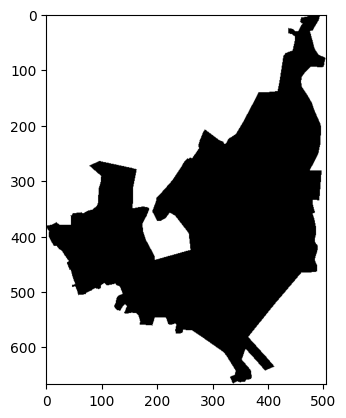

Malad image shape: (667, 505, 64)


In [92]:
with rasterio.open(MALAD_IMAGE) as src:

    if malad_aoi.crs != src.crs:
        malad_aoi = malad_aoi.to_crs(src.crs)

    malad_clip, malad_transform = mask(
        src,
        malad_aoi.geometry,
        crop=True,
        filled=False
    )
    print(type(malad_clip))
    print(malad_clip.shape)

    plt.imshow(malad_clip.mask[0], cmap="gray")
    plt.show()

    malad_profile = src.profile.copy()

malad_clip = np.moveaxis(
    malad_clip.data,
    0,
    -1
)

rows, cols = malad_clip.shape[:2]

print("Malad image shape:", malad_clip.shape)

In [13]:
flat = malad_clip.reshape(-1, malad_clip.shape[-1])

valid_mask = np.all(np.isfinite(flat), axis=1)

# Remove zero embeddings
valid_mask &= np.any(flat != 0, axis=1)

X_target = flat[valid_mask]

print("Target pixels:", X_target.shape)

print("Zero vectors:",
      np.sum(np.all(X_target == 0, axis=1)))

Target pixels: (159808, 64)
Zero vectors: 0


In [52]:
from coral import coral_fit, coral_apply

params = coral_fit(
    X_target,
    X_train
)

aligned_pixels = coral_apply(
    X_target,
    params
)

print(aligned_pixels.shape)

(159808, 64)


In [53]:
print("Any NaN :", np.isnan(aligned_pixels).any())

print("Any Inf :", np.isinf(aligned_pixels).any())

print("Minimum :", aligned_pixels.min())

print("Maximum :", aligned_pixels.max())

Any NaN : False
Any Inf : False
Minimum : -0.60590113564767
Maximum : 0.5895992899359777


In [54]:
species = "A_marina_dense"

# Binary labels
y_binary = (y_train == species).astype(np.uint8)

print(np.unique(y_binary, return_counts=True))

rf_dense = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_dense.fit(X_train, y_binary)

print("Training Accuracy :",
      rf_dense.score(X_train, y_binary))

(array([0, 1], dtype=uint8), array([14448,  2087]))
Training Accuracy : 1.0


In [55]:
prediction = rf_dense.predict(aligned_pixels)

prediction_map = np.full(
    rows * cols,
    -1,
    dtype=np.int16
)

prediction_map[valid_mask] = prediction

prediction_map = prediction_map.reshape(rows, cols)

print(np.unique(prediction_map, return_counts=True))

(array([-1,  0,  1], dtype=int16), array([177027, 152142,   7666]))


In [56]:
dense_file = os.path.join(
    OUTPUT_DIR,
    "Dense_binary.tif"
)

profile = malad_profile.copy()

profile.update(
    count=1,
    dtype=rasterio.int16,
    nodata=-1
)

with rasterio.open(
    dense_file,
    "w",
    **profile
) as dst:

    dst.write(prediction_map, 1)

print(dense_file)

C:\Users\snvra\NISAR_Data_project\classifier models\Dense_binary.tif


In [57]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    confusion_matrix
)

y_true = []
y_pred = []

with rasterio.open(dense_file) as src:

    gt = malad_gt.copy()

    if gt.crs != src.crs:
        gt = gt.to_crs(src.crs)

    for _, row in gt.iterrows():

        # Dense = am01
        true_label = 1 if row["label"] == "am01" else 0

        clipped, _ = mask(
            src,
            [row.geometry],
            crop=True,
            filled=False
        )

        pred = clipped.data[0]
        m = clipped.mask[0]

        pred = pred[~m]
        pred = pred[pred != -1]

        y_true.extend([true_label] * len(pred))
        y_pred.extend(pred.tolist())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Confusion Matrix")
print(confusion_matrix(y_true, y_pred))

print()

print("OA :", accuracy_score(y_true, y_pred))
print("Precision :", precision_score(y_true, y_pred, zero_division=0))
print("Recall :", recall_score(y_true, y_pred, zero_division=0))
print("F1 :", f1_score(y_true, y_pred, zero_division=0))
print("Kappa :", cohen_kappa_score(y_true, y_pred))

Confusion Matrix
[[105  61]
 [207   0]]

OA : 0.28150134048257375
Precision : 0.0
Recall : 0.0
F1 : 0.0
Kappa : -0.3380270378798018


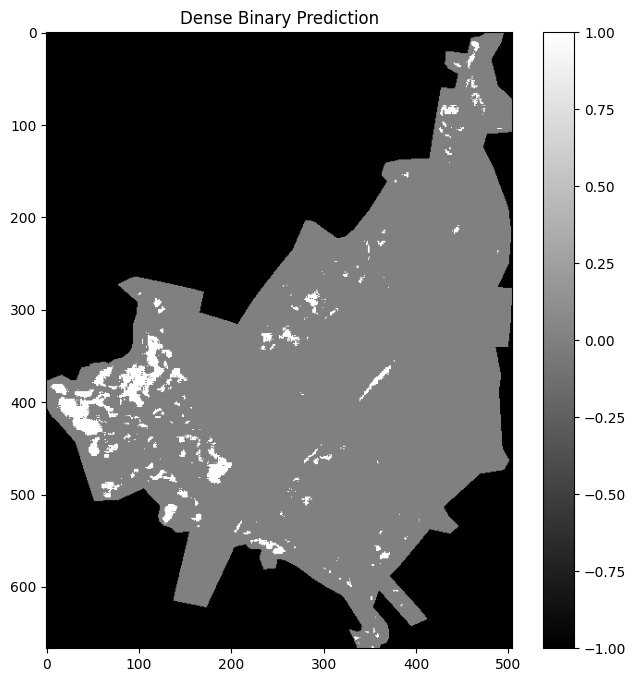

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,8))

plt.imshow(prediction_map, cmap="gray")

plt.title("Dense Binary Prediction")

plt.colorbar()

plt.show()

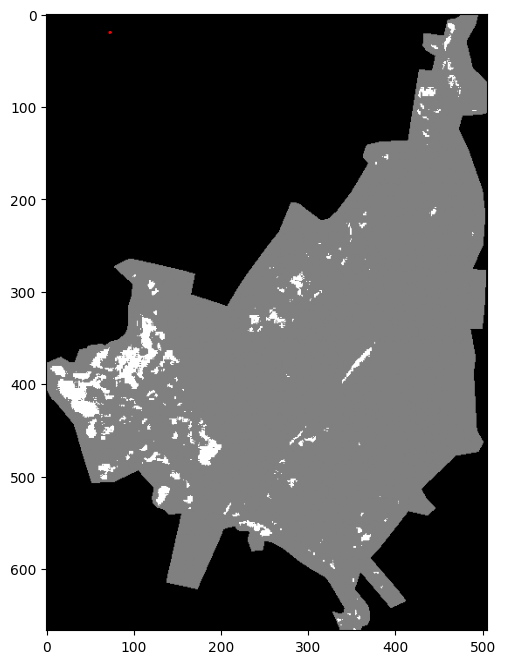

In [63]:
fig, ax = plt.subplots(figsize=(8,8))

ax.imshow(prediction_map, cmap="gray")

malad_gt[malad_gt["label"]=="am01"].boundary.plot(
    ax=ax,
    edgecolor="red",
    linewidth=2
)

plt.show()

In [60]:
print("Krishna mean (first 10 bands)")
print(np.round(X_train.mean(axis=0)[:10], 4))

print()

print("Malad before CORAL")
print(np.round(X_target.mean(axis=0)[:10], 4))

print()

print("Malad after CORAL")
print(np.round(aligned_pixels.mean(axis=0)[:10], 4))

Krishna mean (first 10 bands)
[ 0.0354 -0.0064  0.0519  0.0273 -0.1647  0.0626  0.0486  0.0373 -0.0964
  0.2834]

Malad before CORAL
[ 2.200e-02 -1.615e-01  1.237e-01  1.000e-04 -1.592e-01 -6.600e-03
 -6.530e-02  8.810e-02 -1.424e-01  1.605e-01]

Malad after CORAL
[ 0.0354 -0.0064  0.0519  0.0273 -0.1647  0.0626  0.0486  0.0373 -0.0964
  0.2834]


In [62]:
from coral import covariance_gap

print("Before:", covariance_gap(X_train, X_target))
print("After :", covariance_gap(X_train, aligned_pixels))

Before: 0.11926231424697953
After : 0.0008891712086061163


In [64]:
prob = rf_dense.predict_proba(aligned_pixels)[:, 1]

print(prob.min(), prob.max(), prob.mean())

0.0 0.9833333333333333 0.09148930800293686


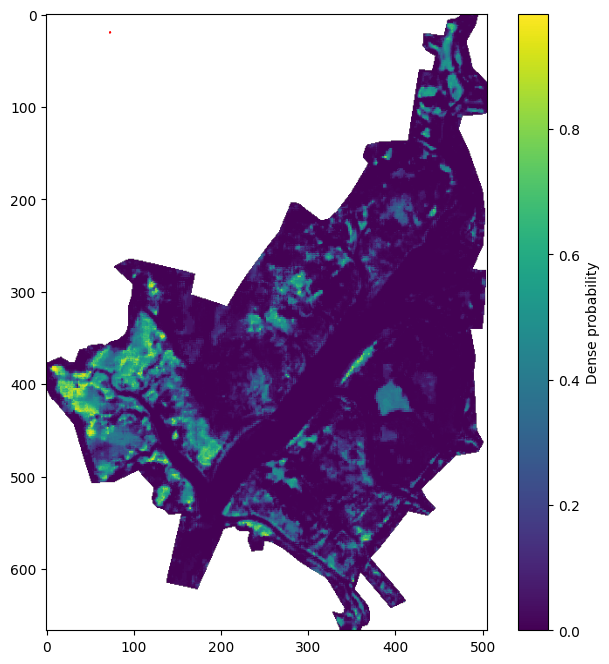

In [65]:
prob_map = np.full(rows * cols, np.nan)

prob_map[valid_mask] = prob

prob_map = prob_map.reshape(rows, cols)

plt.figure(figsize=(8,8))
plt.imshow(prob_map, cmap="viridis")
plt.colorbar(label="Dense probability")

malad_gt[malad_gt["label"]=="am01"].boundary.plot(
    ax=plt.gca(),
    edgecolor="red",
    linewidth=1.5
)

plt.show()

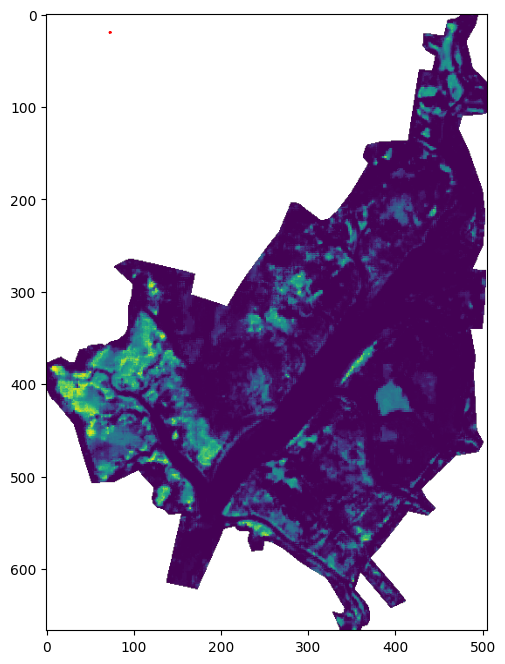

In [66]:
fig, ax = plt.subplots(figsize=(8,8))

ax.imshow(prob_map, cmap="viridis")

malad_gt[malad_gt["label"]=="am01"].boundary.plot(
    ax=ax,
    edgecolor="red",
    linewidth=2
)

plt.show()

In [67]:
prob = rf_dense.predict_proba(aligned_pixels)[:, 1]

print("Minimum :", prob.min())
print("Maximum :", prob.max())

print("Percentiles")
for p in [50, 75, 90, 95, 97, 99]:
    print(p, np.percentile(prob, p))

Minimum : 0.0
Maximum : 0.9833333333333333
Percentiles
50 0.006666666666666667
75 0.09333333333333334
90 0.35333333333333333
95 0.49666666666666665
97 0.57
99 0.7133333333333334


In [68]:
prob = rf_dense.predict_proba(aligned_pixels)[:, 1]
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score
)

thresholds = np.arange(0.10, 0.91, 0.05)

results = []

for th in thresholds:

    prediction = (prob >= th).astype(np.uint8)

    prediction_map = np.full(rows * cols, -1, dtype=np.int16)
    prediction_map[valid_mask] = prediction
    prediction_map = prediction_map.reshape(rows, cols)

    y_true = []
    y_pred = []

    with rasterio.open(MALAD_IMAGE) as src:

        for _, row in malad_gt.iterrows():

            true_label = 1 if row["label"] == "am01" else 0

            clipped, _ = mask(
                src,
                [row.geometry],
                crop=True,
                filled=False
            )

            pred = prediction_map[
                clipped.shape[1]*0:clipped.shape[1],  # placeholder
            ]

In [69]:
from rasterio.features import geometry_mask

results = []

transform = malad_transform

for th in thresholds:

    pred_binary = (prob >= th).astype(np.uint8)

    pred_map = np.full(rows * cols, -1, dtype=np.int16)
    pred_map[valid_mask] = pred_binary
    pred_map = pred_map.reshape(rows, cols)

    y_true = []
    y_pred = []

    for _, row in malad_gt.iterrows():

        mask_geom = geometry_mask(
            [row.geometry],
            transform=transform,
            invert=True,
            out_shape=(rows, cols)
        )

        pred_pixels = pred_map[mask_geom]

        pred_pixels = pred_pixels[pred_pixels != -1]

        if len(pred_pixels) == 0:
            continue

        gt_value = 1 if row["label"] == "am01" else 0

        y_true.extend([gt_value] * len(pred_pixels))
        y_pred.extend(pred_pixels.tolist())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    oa = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    kappa = cohen_kappa_score(y_true, y_pred)

    results.append([
        th,
        oa,
        precision,
        recall,
        f1,
        kappa
    ])

In [70]:
results = pd.DataFrame(
    results,
    columns=[
        "Threshold",
        "OA",
        "Precision",
        "Recall",
        "F1",
        "Kappa"
    ]
)

results

,Threshold,OA,Precision,Recall,F1,Kappa
0,0.10,0.203753,0.244318,0.207729,0.224543,-0.582699
1,0.15,0.163539,0.173913,0.135266,0.152174,-0.648152
2,0.20,0.112601,0.063380,0.043478,0.051576,-0.729440
3,0.25,0.099196,0.015038,0.009662,0.011765,-0.746537
4,0.30,0.107239,0.000000,0.000000,0.000000,-0.724047
5,0.35,0.144772,0.000000,0.000000,0.000000,-0.638511
6,0.40,0.214477,0.000000,0.000000,0.000000,-0.483192
7,0.45,0.292225,0.000000,0.000000,0.000000,-0.315169
8,0.50,0.327078,0.000000,0.000000,0.000000,-0.241569
9,0.55,0.353887,0.000000,0.000000,0.000000,-0.185658


In [71]:
best = results.sort_values(
    "F1",
    ascending=False
).iloc[0]

print(best)

Threshold    0.100000
OA           0.203753
Precision    0.244318
Recall       0.207729
F1           0.224543
Kappa       -0.582699
Name: 0, dtype: float64


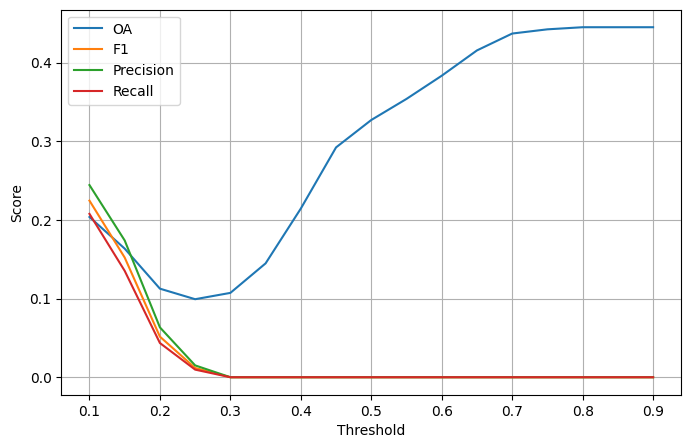

In [72]:
plt.figure(figsize=(8,5))

plt.plot(results["Threshold"], results["OA"], label="OA")
plt.plot(results["Threshold"], results["F1"], label="F1")
plt.plot(results["Threshold"], results["Precision"], label="Precision")
plt.plot(results["Threshold"], results["Recall"], label="Recall")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.grid(True)
plt.legend()

plt.show()

In [73]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_true, prob_values)  # probabilities at GT pixels
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

print("AUC =", roc_auc)

NameError: name 'prob_values' is not defined

In [74]:
from rasterio.features import geometry_mask

y_true = []
prob_values = []

transform = malad_transform

# Probability map
prob_map = np.full(rows * cols, np.nan)
prob_map[valid_mask] = prob
prob_map = prob_map.reshape(rows, cols)

for _, row in malad_gt.iterrows():

    mask_geom = geometry_mask(
        [row.geometry],
        transform=transform,
        invert=True,
        out_shape=(rows, cols)
    )

    probs = prob_map[mask_geom]

    probs = probs[~np.isnan(probs)]

    if len(probs) == 0:
        continue

    gt_value = 1 if row["label"] == "am01" else 0

    y_true.extend([gt_value] * len(probs))
    prob_values.extend(probs.tolist())

y_true = np.array(y_true)
prob_values = np.array(prob_values)

print(len(y_true), len(prob_values))

373 373


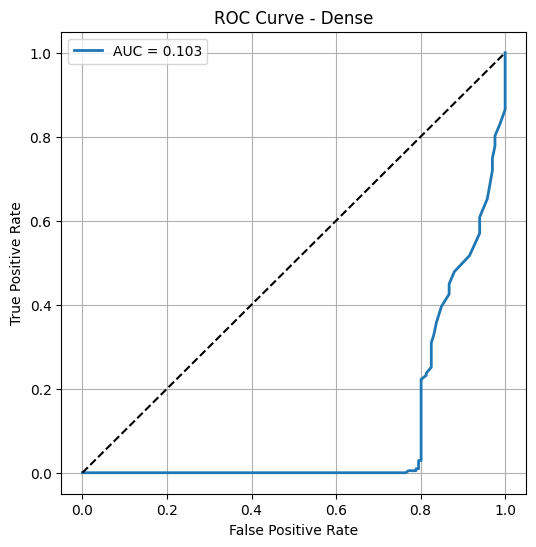

AUC : 0.10293347302252488


In [75]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_true, prob_values)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,6))

plt.plot(fpr, tpr, lw=2,
         label=f"AUC = {roc_auc:.3f}")

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Dense")

plt.grid(True)
plt.legend()

plt.show()

print("AUC :", roc_auc)

In [76]:
print(np.unique(y_true, return_counts=True))
print(prob_values[y_true == 1][:20])
print(prob_values[y_true == 0][:20])

(array([0, 1]), array([166, 207]))
[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.02       0.02
 0.17666667 0.15333333]
[0.21333333 0.44       0.47666667 0.01333333 0.48       0.5
 0.35666667 0.51       0.36       0.37666667 0.40333333 0.68666667
 0.59666667 0.68       0.47333333 0.47333333 0.32333333 0.24
 0.61666667 0.55      ]


In [77]:
print("Mean probability for Dense GT:",
      np.mean(prob_values[y_true == 1]))

print("Mean probability for Non-Dense GT:",
      np.mean(prob_values[y_true == 0]))

Mean probability for Dense GT: 0.05727858293075684
Mean probability for Non-Dense GT: 0.37853413654618473


In [78]:
print(malad_gt["label"].value_counts())

label
rh      1
am01    1
am02    1
Name: count, dtype: int64


In [79]:
print("Dense mean:",
      np.mean(prob_values[y_true==1]))

print("Non-Dense mean:",
      np.mean(prob_values[y_true==0]))

Dense mean: 0.05727858293075684
Non-Dense mean: 0.37853413654618473


In [80]:
print("Dense median:",
      np.median(prob_values[y_true==1]))

print("Non-Dense median:",
      np.median(prob_values[y_true==0]))

Dense median: 0.03333333333333333
Non-Dense median: 0.4066666666666666


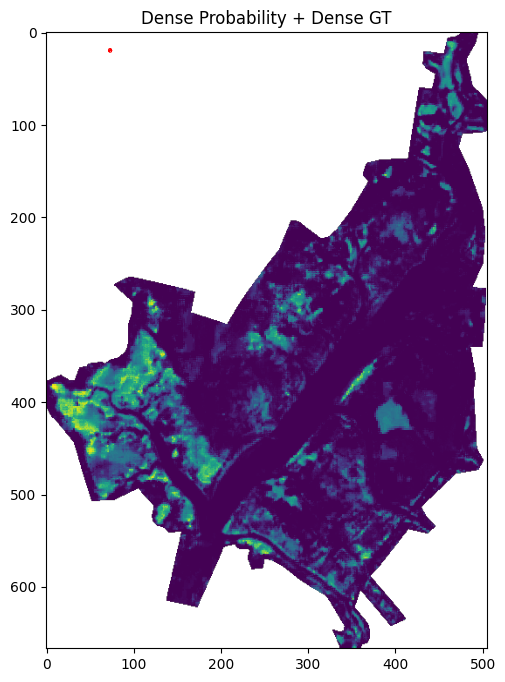

In [81]:
fig, ax = plt.subplots(figsize=(8,8))

ax.imshow(prob_map, cmap="viridis")

malad_gt[malad_gt["label"]=="am01"].boundary.plot(
    ax=ax,
    edgecolor="red",
    linewidth=3
)

plt.title("Dense Probability + Dense GT")
plt.show()

In [82]:
print("Prediction transform")
print(malad_transform)

print()

print("GT bounds")
print(malad_gt.total_bounds)

print()

print("AOI bounds")
print(malad_aoi.total_bounds)

Prediction transform
| 0.00, 0.00, 72.79|
| 0.00,-0.00, 19.20|
| 0.00, 0.00, 1.00|

GT bounds
[72.78839242 19.15133242 72.83017974 19.18012274]

AOI bounds
[72.78699532 19.1360486  72.83229332 19.19586349]


In [83]:
print("Prediction shape")
print(rows, cols)

Prediction shape
667 505


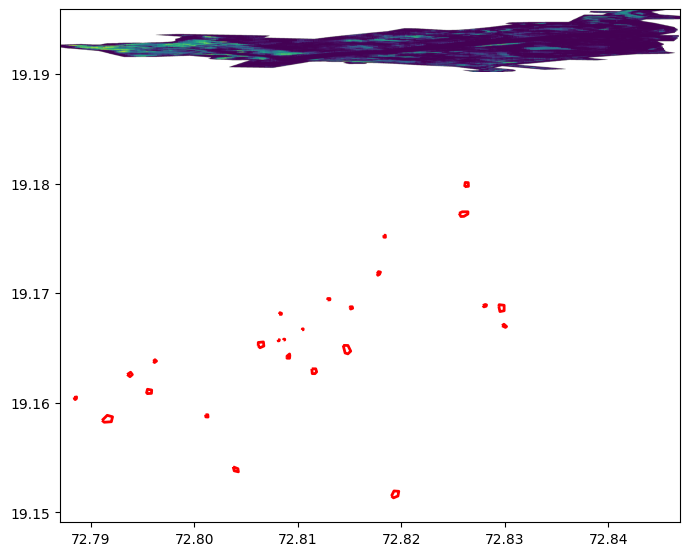

In [84]:
from rasterio.plot import plotting_extent

extent = plotting_extent(
    malad_clip.transpose(2,0,1),
    malad_transform
)

fig, ax = plt.subplots(figsize=(8,8))

ax.imshow(
    prob_map,
    extent=extent,
    origin="upper",
    cmap="viridis"
)

malad_gt.boundary.plot(
    ax=ax,
    edgecolor="red",
    linewidth=2
)

plt.show()

In [85]:
with rasterio.open(MALAD_IMAGE) as src:

    print("Original raster bounds:")
    print(src.bounds)

    print()

    print("Original transform:")
    print(src.transform)

    print()

    print("Original shape:")
    print(src.height, src.width)

Original raster bounds:
BoundingBox(left=72.78680437953993, bottom=19.13384605716057, right=72.83360660584256, top=19.19591964329323)

Original transform:
| 0.00, 0.00, 72.79|
| 0.00,-0.00, 19.20|
| 0.00, 0.00, 1.00|

Original shape:
691 521


In [86]:
print("Cropped transform")
print(malad_transform)

print()

print("Cropped shape")
print(rows, cols)

Cropped transform
| 0.00, 0.00, 72.79|
| 0.00,-0.00, 19.20|
| 0.00, 0.00, 1.00|

Cropped shape
667 505


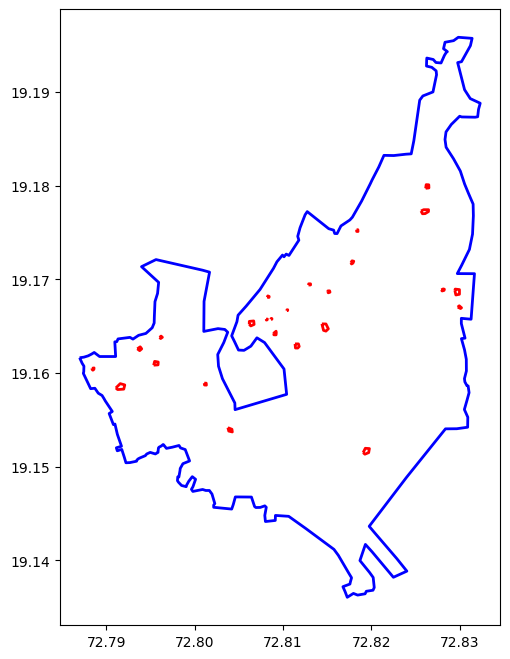

In [87]:
fig, ax = plt.subplots(figsize=(8,8))

malad_aoi.boundary.plot(
    ax=ax,
    edgecolor="blue",
    linewidth=2
)

malad_gt.boundary.plot(
    ax=ax,
    edgecolor="red",
    linewidth=2
)

plt.show()

In [88]:
with rasterio.open(MALAD_IMAGE) as src:
    print(src.bounds)
    print(src.width, src.height)

BoundingBox(left=72.78680437953993, bottom=19.13384605716057, right=72.83360660584256, top=19.19591964329323)
521 691


In [89]:
print(malad_aoi)

print("Number of AOI geometries:", len(malad_aoi))
print("Geometry type:", malad_aoi.geometry.iloc[0].geom_type)

print("AOI area:", malad_aoi.area)

   OBJECTID  Name  SHAPE_Leng  SHAPE_Area  \
0         6  None    0.265047    0.001106   

                                            geometry  
0  POLYGON ((72.78741 19.15997, 72.78746 19.16014...  
Number of AOI geometries: 1
Geometry type: Polygon
AOI area: 0    0.001106
dtype: float64


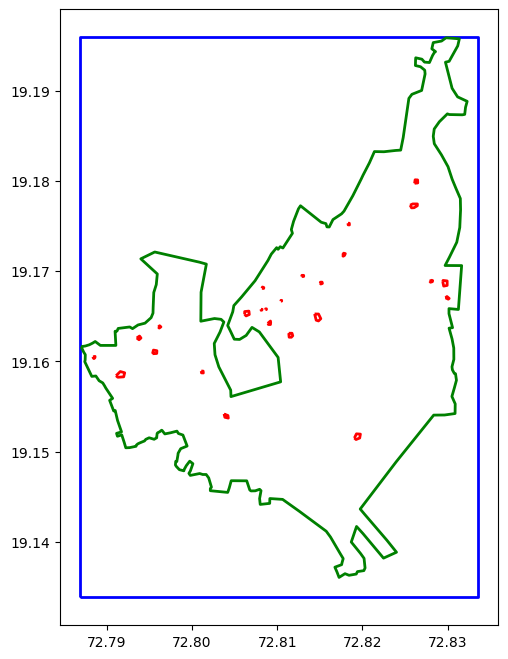

In [90]:
from shapely.geometry import box

with rasterio.open(MALAD_IMAGE) as src:
    raster_box = gpd.GeoDataFrame(
        geometry=[box(*src.bounds)],
        crs=src.crs
    )

fig, ax = plt.subplots(figsize=(8,8))

raster_box.boundary.plot(ax=ax, edgecolor="blue", linewidth=2, label="Raster")
malad_aoi.boundary.plot(ax=ax, edgecolor="green", linewidth=2, label="AOI")
malad_gt.boundary.plot(ax=ax, edgecolor="red", linewidth=2, label="GT")

plt.show()

In [93]:
print(valid_mask.shape)
print(valid_mask.sum())
print(rows * cols)

(336835,)
159808
336835


In [94]:
from rasterio.features import geometry_mask

transform = malad_transform

for _, row in malad_gt.iterrows():

    mask_geom = geometry_mask(
        [row.geometry],
        transform=transform,
        invert=True,
        out_shape=(rows, cols)
    )

    values = prob_map[mask_geom]
    values = values[~np.isnan(values)]

    print("--------------------------------")
    print("Label :", row["label"])
    print("Pixels :", len(values))
    print("Mean :", values.mean())
    print("Median :", np.median(values))
    print("Max :", values.max())

--------------------------------
Label : rh
Pixels : 46
Mean : 0.5041304347826088
Median : 0.53
Max : 0.7633333333333333
--------------------------------
Label : am01
Pixels : 207
Mean : 0.05727858293075684
Median : 0.03333333333333333
Max : 0.2733333333333333
--------------------------------
Label : am02
Pixels : 120
Mean : 0.33038888888888884
Median : 0.39
Max : 0.6366666666666667


In [95]:
species_list = [
    "A_marina_dense",
    "A_marina_moderate",
    "Rhizophora_sp"
]

rf_models = {}

for species in species_list:

    print("Training", species)

    y_binary = (y_train == species).astype(np.uint8)

    rf = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_binary)

    print("Training Accuracy:",
          rf.score(X_train, y_binary))

    rf_models[species] = rf

Training A_marina_dense
Training Accuracy: 1.0
Training A_marina_moderate
Training Accuracy: 1.0
Training Rhizophora_sp
Training Accuracy: 1.0


In [96]:
prob_maps = {}

for species in species_list:

    print("Predicting:", species)

    prob = rf_models[species].predict_proba(aligned_pixels)[:,1]

    prob_map = np.full(
        rows * cols,
        np.nan,
        dtype=np.float32
    )

    prob_map[valid_mask] = prob

    prob_map = prob_map.reshape(rows, cols)

    prob_maps[species] = prob_map

Predicting: A_marina_dense
Predicting: A_marina_moderate
Predicting: Rhizophora_sp


In [97]:
from rasterio.features import geometry_mask

results = []

gt_classes = [
    "am01",
    "am02",
    "rh"
]

name_map = {
    "A_marina_dense":"Dense RF",
    "A_marina_moderate":"Moderate RF",
    "Rhizophora_sp":"Rhizophora RF"
}

for _, row in malad_gt.iterrows():

    gt_label = row["label"]

    mask_geom = geometry_mask(
        [row.geometry],
        transform=malad_transform,
        invert=True,
        out_shape=(rows, cols)
    )

    record = {
        "GT":gt_label
    }

    for species in species_list:

        values = prob_maps[species][mask_geom]

        values = values[~np.isnan(values)]

        record[name_map[species]] = np.mean(values)

    results.append(record)

In [98]:
df = pd.DataFrame(results)

matrix = df.groupby("GT").mean()

matrix

,Dense RF,Moderate RF,Rhizophora RF
GT,,,
am01,0.057279,0.016135,0.006828
am02,0.330389,0.219389,0.090361
rh,0.504130,0.117971,0.490145


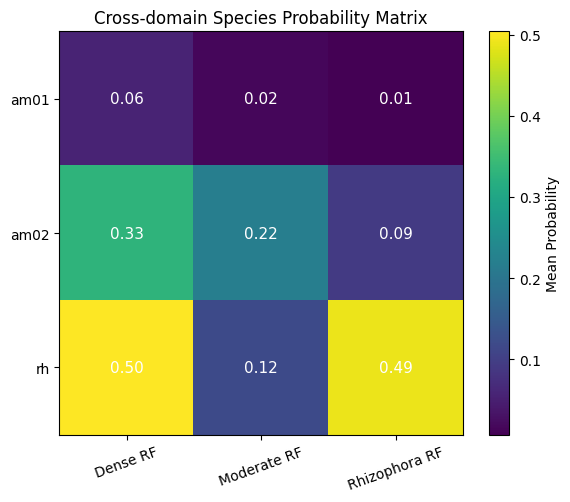

In [99]:
plt.figure(figsize=(6,5))

plt.imshow(matrix.values, cmap="viridis")

plt.xticks(
    range(len(matrix.columns)),
    matrix.columns,
    rotation=20
)

plt.yticks(
    range(len(matrix.index)),
    matrix.index
)

plt.colorbar(label="Mean Probability")

for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        plt.text(
            j,
            i,
            f"{matrix.iloc[i,j]:.2f}",
            ha="center",
            va="center",
            color="white",
            fontsize=11
        )

plt.title("Cross-domain Species Probability Matrix")

plt.tight_layout()

plt.show()

In [102]:
from sklearn.manifold import TSNE
import numpy as np

np.random.seed(42)

n = 3000

krishna_idx = np.random.choice(
    X_train.shape[0],
    n,
    replace=False
)

malad_idx = np.random.choice(
    X_target.shape[0],
    n,
    replace=False
)

Xk = X_train[krishna_idx]
Xm_before = X_target[malad_idx]
Xm_after = aligned_pixels[malad_idx]

In [103]:
X_before = np.vstack([Xk, Xm_before])

labels_before = np.array(
    ["Krishna"] * n +
    ["Malad"] * n
)

tsne_before = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=42
)

emb_before = tsne_before.fit_transform(X_before)

In [104]:
X_after = np.vstack([Xk, Xm_after])

labels_after = np.array(
    ["Krishna"] * n +
    ["Malad"] * n
)

tsne_after = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=42
)

emb_after = tsne_after.fit_transform(X_after)

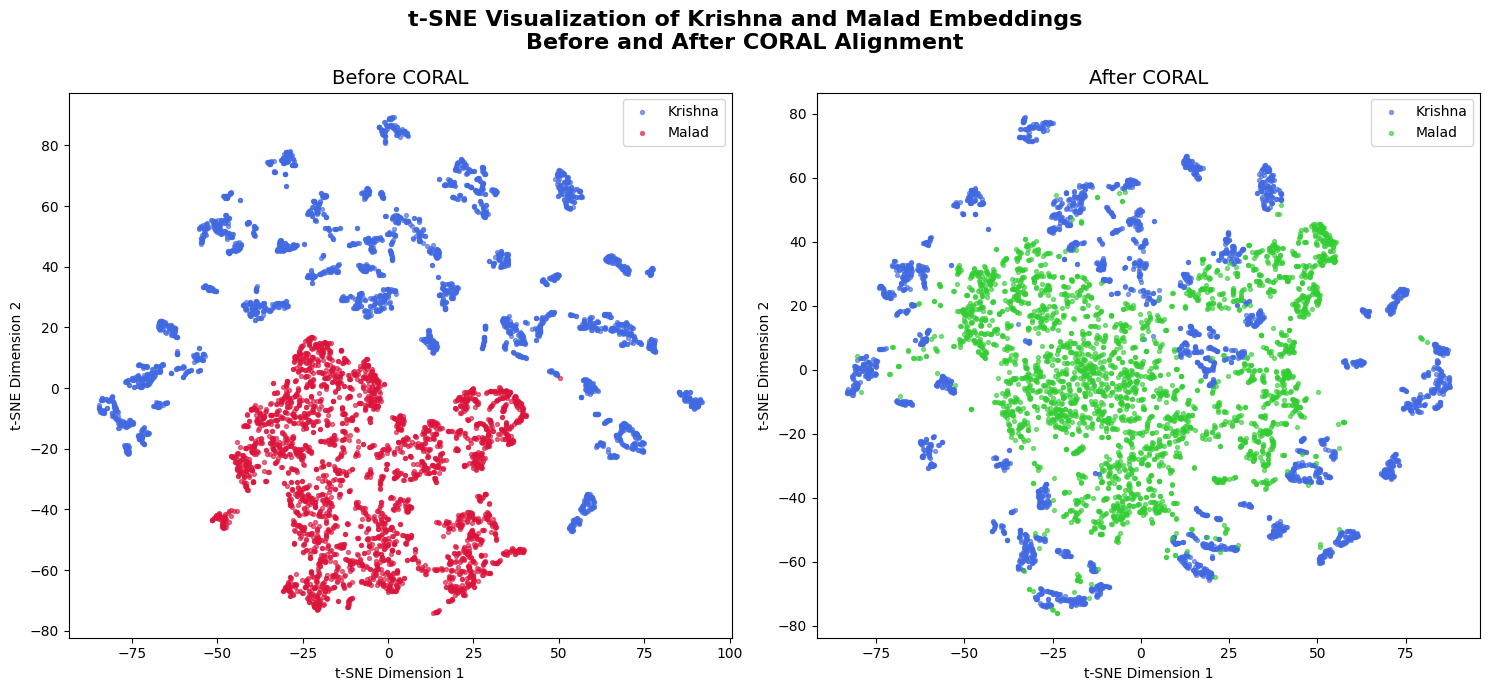

In [105]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# ----------------------------
# BEFORE CORAL
# ----------------------------
ax = axes[0]

idx = labels_before == "Krishna"
ax.scatter(
    emb_before[idx,0],
    emb_before[idx,1],
    s=8,
    alpha=0.6,
    c="royalblue",
    label="Krishna"
)

idx = labels_before == "Malad"
ax.scatter(
    emb_before[idx,0],
    emb_before[idx,1],
    s=8,
    alpha=0.6,
    c="crimson",
    label="Malad"
)

ax.set_title("Before CORAL", fontsize=14)
ax.set_xlabel("t-SNE Dimension 1")
ax.set_ylabel("t-SNE Dimension 2")
ax.legend()

# ----------------------------
# AFTER CORAL
# ----------------------------
ax = axes[1]

idx = labels_after == "Krishna"
ax.scatter(
    emb_after[idx,0],
    emb_after[idx,1],
    s=8,
    alpha=0.6,
    c="royalblue",
    label="Krishna"
)

idx = labels_after == "Malad"
ax.scatter(
    emb_after[idx,0],
    emb_after[idx,1],
    s=8,
    alpha=0.6,
    c="limegreen",
    label="Malad"
)

ax.set_title("After CORAL", fontsize=14)
ax.set_xlabel("t-SNE Dimension 1")
ax.set_ylabel("t-SNE Dimension 2")
ax.legend()

plt.suptitle(
    "t-SNE Visualization of Krishna and Malad Embeddings\nBefore and After CORAL Alignment",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

In [106]:
from sklearn.decomposition import PCA
np.random.seed(42)

n = 3000

krishna_idx = np.random.choice(X_train.shape[0], n, replace=False)
malad_idx   = np.random.choice(X_target.shape[0], n, replace=False)

Xk = X_train[krishna_idx]
Xm_before = X_target[malad_idx]
Xm_after  = aligned_pixels[malad_idx]

In [107]:
X_all = np.vstack([
    Xk,
    Xm_before,
    Xm_after
])

pca = PCA(n_components=2)

embedding = pca.fit_transform(X_all)

In [108]:
emb_k = embedding[:n]

emb_before = embedding[n:2*n]

emb_after = embedding[2*n:]

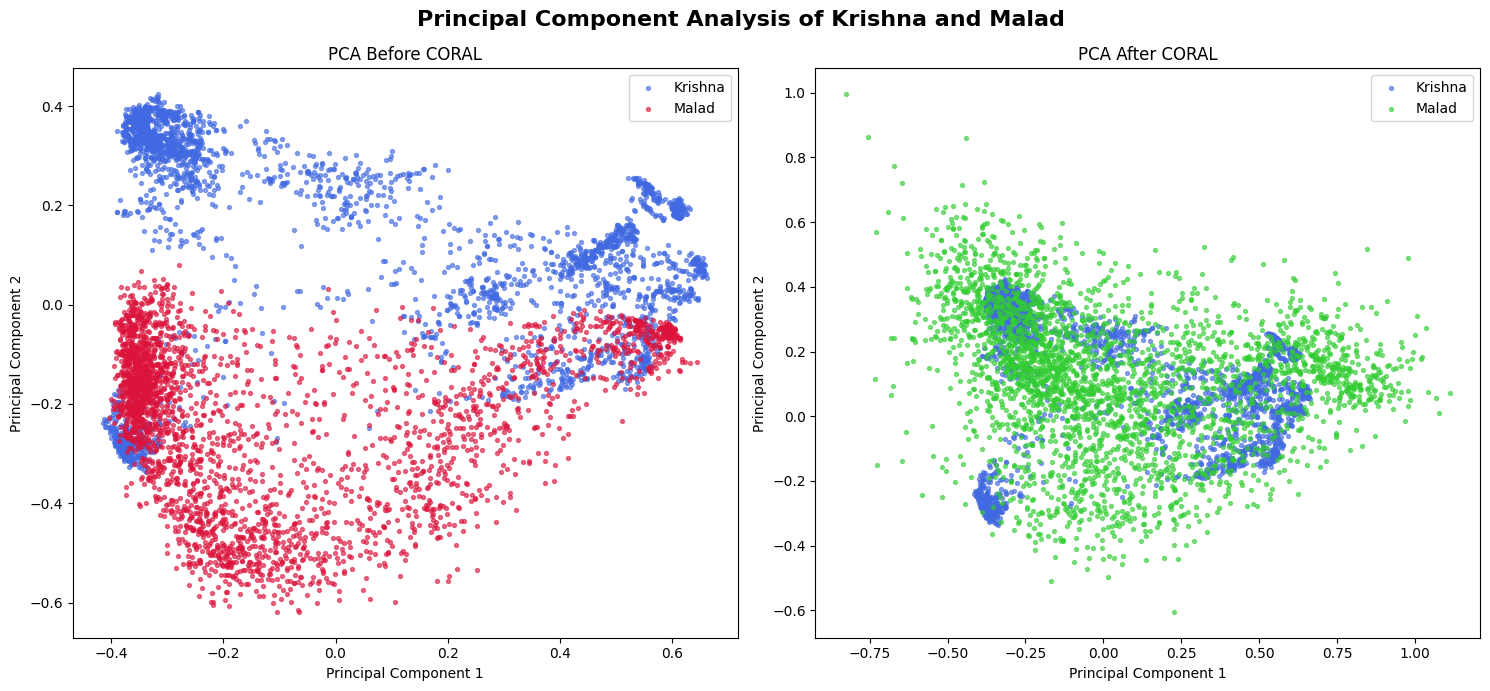

In [110]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1,2,figsize=(15,7))

# ==========================
# BEFORE CORAL
# ==========================

ax = axes[0]

ax.scatter(
    emb_k[:,0],
    emb_k[:,1],
    s=8,
    c="royalblue",
    alpha=0.6,
    label="Krishna"
)

ax.scatter(
    emb_before[:,0],
    emb_before[:,1],
    s=8,
    c="crimson",
    alpha=0.6,
    label="Malad"
)

ax.set_title("PCA Before CORAL")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.legend()

# ==========================
# AFTER CORAL
# ==========================

ax = axes[1]

ax.scatter(
    emb_k[:,0],
    emb_k[:,1],
    s=8,
    c="royalblue",
    alpha=0.6,
    label="Krishna"
)

ax.scatter(
    emb_after[:,0],
    emb_after[:,1],
    s=8,
    c="limegreen",
    alpha=0.6,
    label="Malad"
)

ax.set_title("PCA After CORAL")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.legend()

plt.suptitle(
    "Principal Component Analysis of Krishna and Malad ",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.show()